# Hybrid Images: Man + Cat

## Goal

Create a **hybrid image** by combining the low-frequency content of one image (a man) with the high-frequency content of another (a cat). The result looks like the man from a distance (low frequencies dominate) and like the cat up close (high frequencies dominate).

We build everything from scratch:

- Grayscale conversion using Rec. 601 luminance weights.
- 1-D Gaussian kernel and separable 2-D convolution with reflect padding.
- Low-pass and high-pass filtering via Gaussian blur.
- Multi-sigma tuning sweep to pick the best cutoff.

## Hybrid image equation

$$
I_{\text{hybrid}} = \underbrace{I_{\text{low}} * G_{\sigma_{\text{low}}}}_{\text{low-pass}} \;+\; \underbrace{I_{\text{high}} - I_{\text{high}} * G_{\sigma_{\text{high}}}}_{\text{high-pass}}
$$

## Gaussian kernel

$$
G(x) = \frac{\exp\!\left(-x^{2}/(2\sigma^{2})\right)}{\sum_{x'} \exp\!\left(-{x'}^{2}/(2\sigma^{2})\right)}
$$

## 1 — Environment setup

Same convention as the rest of the lab: resolve `ROOT`, put the starter pack on the path, and reuse `load_image` and `align_images`.

In [1]:
from pathlib import Path
import sys
# %pip install "numpy<2" --force-reinstall
import matplotlib.pyplot as plt
import numpy as np

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT))
IMAGE_DIR = ROOT / "starter_pack" / "images" / "part2_frequencies"
OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

from starter_pack.code.align_images import align_images
from starter_pack.code.utils import load_image

plt.rcParams["figure.dpi"] = 100

## 2 — Utility functions

- `rgb_to_gray`: Rec. 601 luminance $0.299R + 0.587G + 0.114B$.
- `gaussian_kernel`: normalized 1-D Gaussian of width $\sigma$.
- `convolve_1d_reflect`: 1-D convolution with reflect padding.
- `convolve_reflect`: 2-D separable convolution (rows then columns).
- `gaussian_blur`: full 2-D Gaussian blur for grayscale or RGB input.

In [2]:
def rgb_to_gray(image):
    # grayscale = 0.299*R + 0.587*G + 0.114*B
    if image.ndim == 2:
        return image.astype(np.float32)
    return (0.299 * image[:, :, 0]
            + 0.587 * image[:, :, 1]
            + 0.114 * image[:, :, 2]).astype(np.float32)


def gaussian_kernel(sigma, radius=None):
    if sigma <= 0:
        raise ValueError("sigma must be positive")
    if radius is None:
        radius = int(np.ceil(3 * sigma))
    coordinates = np.arange(-radius, radius + 1, dtype=np.float32)
    kernel = np.exp(-(coordinates ** 2) / (2 * sigma ** 2))
    return kernel / kernel.sum()


def convolve_1d_reflect(image, kernel, axis):
    radius = len(kernel) // 2
    if axis == 0:
        padded = np.pad(image, ((radius, radius), (0, 0)), mode="reflect")
        result = np.empty_like(image, dtype=np.float32)
        for row in range(image.shape[0]):
            result[row] = np.sum(padded[row:row + len(kernel)] * kernel[:, None], axis=0)
    elif axis == 1:
        padded = np.pad(image, ((0, 0), (radius, radius)), mode="reflect")
        result = np.empty_like(image, dtype=np.float32)
        for column in range(image.shape[1]):
            result[:, column] = np.sum(padded[:, column:column + len(kernel)] * kernel[None, :], axis=1)
    else:
        raise ValueError("axis must be 0 (rows) or 1 (columns)")
    return result


def convolve_reflect(image, kernel):
    if image.ndim != 2:
        raise ValueError(f"Expected a 2-D image, got shape {image.shape}")
    horizontal = convolve_1d_reflect(image, kernel, axis=1)
    return convolve_1d_reflect(horizontal, kernel, axis=0)


def gaussian_blur(image, sigma):
    if image.ndim not in (2, 3):
        raise ValueError(f"Expected a 2-D or 3-D image, got shape {image.shape}")
    kernel = gaussian_kernel(sigma)
    if image.ndim == 2:
        return convolve_reflect(image, kernel)
    channels = [convolve_reflect(image[:, :, channel], kernel) for channel in range(image.shape[2])]
    return np.stack(channels, axis=2)

## 3 — Hybrid image functions

- `make_hybrid`: returns `(low_frequency, high_frequency, hybrid)`.
- `compare_sigmas`: plots a horizontal strip of hybrids across candidate $\sigma$ values.
- `display_hybrid`: shows the full 5-stage pipeline (low source, high source, low-pass, high-pass, hybrid).

In [3]:
def make_hybrid(low_source, high_source, low_sigma, high_sigma):
    low_frequency = gaussian_blur(low_source, low_sigma)
    high_frequency = high_source - gaussian_blur(high_source, high_sigma)
    hybrid = low_frequency + high_frequency
    return low_frequency, high_frequency, hybrid


def compare_sigmas(name, low_source, high_source, sigmas):
    """Computes and renders a horizontal strip of hybrids across candidate sigmas."""
    fig, axes = plt.subplots(1, len(sigmas), figsize=(3.0 * len(sigmas), 3.5))
    if len(sigmas) == 1:
        axes = [axes]

    is_gray = (low_source.ndim == 2)
    cmap = "gray" if is_gray else None

    for ax, s in zip(axes, sigmas):
        print(f"[{name}] Testing sigma = {s}...")
        _, _, hybrid = make_hybrid(low_source, high_source, low_sigma=s, high_sigma=s)
        ax.imshow(np.clip(hybrid, 0, 1), cmap=cmap)
        ax.set_title(f"$\\sigma$ = {s}")
        ax.axis("off")

    fig.suptitle(f"{name} (Multi-Sigma Tuning Sweep)", fontsize=13)
    plt.tight_layout()
    plt.show()


def display_hybrid(name, low_source, high_source, low_frequency, high_frequency, hybrid):
    """Displays the 5-stage decomposition pipeline for the selected cutoff."""
    fig, axes = plt.subplots(1, 5, figsize=(20, 4))
    images = [low_source, high_source, low_frequency, high_frequency + 0.5, hybrid]
    titles = [
        "low-frequency source",
        "high-frequency source",
        "low-pass",
        "high-pass (shifted)",
        "hybrid",
    ]
    is_gray = (low_source.ndim == 2)
    cmap = "gray" if is_gray else None

    for axis, image, title in zip(axes, images, titles):
        axis.imshow(np.clip(image, 0, 1), cmap=cmap)
        axis.set_title(title)
        axis.axis("off")

    fig.suptitle(name, fontsize=14)
    plt.tight_layout()
    plt.show()

## 4 — Load, align, and convert to grayscale

We load the two sources, align them using manually selected eye points, then convert both to grayscale so the hybrid isn't dominated by color differences.

In [4]:
man = load_image(IMAGE_DIR / "hybrid_man.jpg")
cat = load_image(IMAGE_DIR / "hybrid_cat.jpg")

man_eye_points = [(299, 341), (443, 332)]
cat_eye_points = [(605, 290), (760, 372)]
cat_aligned = align_images(man, cat, man_eye_points, cat_eye_points)

man_gray = rgb_to_gray(man)
cat_aligned_gray = rgb_to_gray(cat_aligned)

print(f"man_gray shape:         {man_gray.shape}")
print(f"cat_aligned_gray shape: {cat_aligned_gray.shape}")

man_gray shape:         (1024, 732)
cat_aligned_gray shape: (1024, 732)


## 5 — Multi-sigma empirical sweep

We test a wide range of $\sigma$ to cover different regimes:

- $\sigma \in \{1, 2\}$: fine texture cutoff — keeps almost all detail.
- $\sigma \in \{5, 10\}$: medium cutoff — separates the two sources cleanly.
- $\sigma \in \{20, 35\}$: heavy blur — human silhouette dominates at all scales.

[Man + Cat (Grayscale)] Testing sigma = 1...
[Man + Cat (Grayscale)] Testing sigma = 2...
[Man + Cat (Grayscale)] Testing sigma = 5...
[Man + Cat (Grayscale)] Testing sigma = 10...
[Man + Cat (Grayscale)] Testing sigma = 20...
[Man + Cat (Grayscale)] Testing sigma = 35...


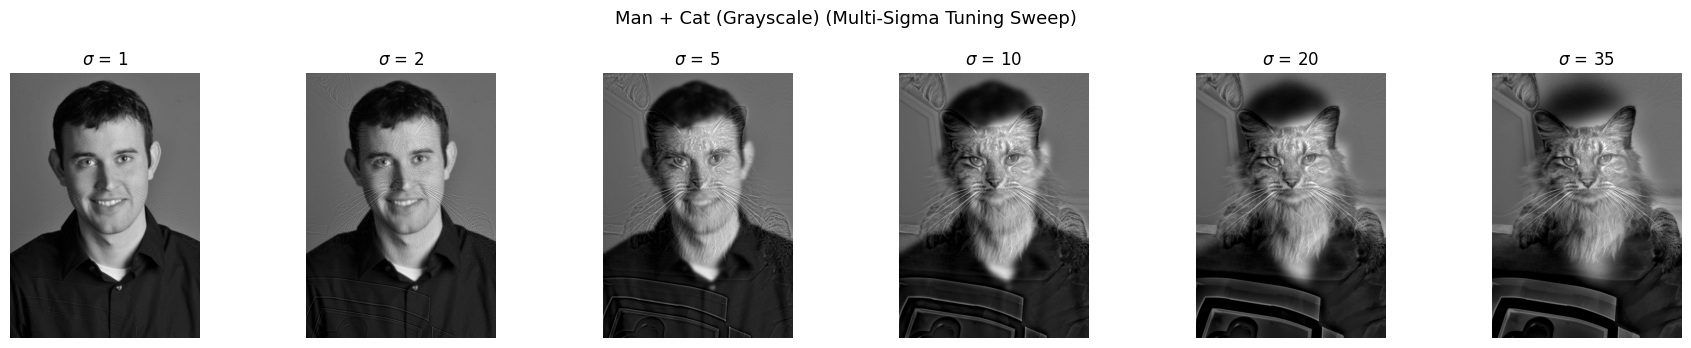

In [5]:
sigmas_man_cat = [1, 2, 5, 10, 20, 35]
compare_sigmas("Man + Cat (Grayscale)", man_gray, cat_aligned_gray, sigmas_man_cat)

## 6 — Final result with the best sigma ($\sigma = 10$)

After running multiple iterations over $[1, 2, 5, 10, 20, 35]$, $\sigma = 10$ was selected as the optimal cutoff for Man + Cat:

- Low $\sigma$ (< 10) retains too many human edges, muddying the cat details up close.
- High $\sigma$ (> 10) blurs the human silhouette too much and leaves cat ghosting artifacts.
- $\sigma = 10$ cleanly isolates close-up whiskers/eyes while preserving face shape at distance.

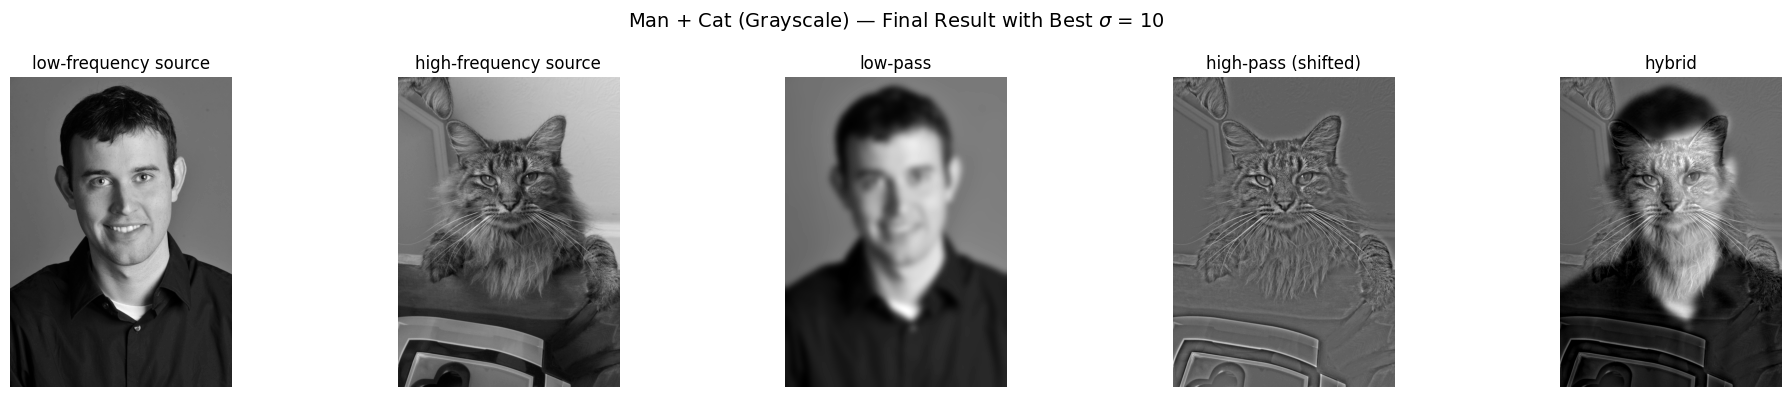

In [6]:
best_sigma = 10
man_low, cat_high, man_cat_hybrid = make_hybrid(
    man_gray, cat_aligned_gray, low_sigma=best_sigma, high_sigma=best_sigma
)

display_hybrid(
    f"Man + Cat (Grayscale) — Final Result with Best $\\sigma$ = {best_sigma}",
    man_gray, cat_aligned_gray, man_low, cat_high, man_cat_hybrid
)

## 7 — Sanity checks

Verify that:

- The aligned cat has the same shape as the man.
- `cat_high` matches its expected definition $\text{cat} - \text{blur}(\text{cat}, 10)$.
- `gaussian_blur` preserves shape and kernel sums to 1.
- Blurring a constant image leaves it unchanged.
- The hybrid image contains no NaN or Inf values.

In [7]:
cat_high_expected = cat_aligned_gray - gaussian_blur(cat_aligned_gray, 10)

assert cat_aligned_gray.shape == man_gray.shape
assert np.allclose(cat_high, cat_high_expected)
assert gaussian_blur(man_gray, 10).shape == man_gray.shape
assert np.isclose(gaussian_kernel(3).sum(), 1)
constant = np.ones((9, 9), dtype=np.float32)
assert np.allclose(gaussian_blur(constant, 2), constant)
assert np.isfinite(man_cat_hybrid).all()

print("All Man + Cat checks passed successfully.")

All Man + Cat checks passed successfully.
